In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent
sys.path.insert(0, str(ROOT_DIR))



In [2]:
from src.data.validation import build_manifest

DATASET_DIR = Path("../data/raw/classification").resolve()

manifest = build_manifest(DATASET_DIR)

OUTPUT_PATH = Path("../artifacts/classification/manifest.csv")

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

manifest.to_csv(OUTPUT_PATH, index=False)


In [3]:
from src.data.splitting import split_dataset , export_classification_splits

train_df, val_df, test_df = split_dataset(manifest)


In [4]:

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"\n{name}: {len(df)} images")
    print(df["label"].value_counts().sort_index())


Train: 4916 images
label
glioma        1135
meningioma    1151
notumor       1400
pituitary     1230
Name: count, dtype: int64

Validation: 1053 images
label
glioma        243
meningioma    247
notumor       300
pituitary     263
Name: count, dtype: int64

Test: 1054 images
label
glioma        243
meningioma    247
notumor       300
pituitary     264
Name: count, dtype: int64


In [5]:
split = {
    "train" : train_df,
    "valid":val_df,
    "test":test_df
}

export_classification_splits(splits=split,output_dir="../data/processed/classification",
)

FileExistsError: Destination déjà existante : ..\data\processed\classification\train\glioma\Te-gl_0284.jpg

In [4]:
from src.classification.dataset import load_classification_image

train_ds, val_ds, test_ds, class_names = (
    load_classification_image(data_dir="../data/processed/classification/")
)

print("Classes :", class_names)

for images, labels in train_ds.take(1):
    print("Dimensions des images :", images.shape)
    print("Dimensions des labels :", labels.shape)
    print("Type des images :", images.dtype)

Found 4916 files belonging to 4 classes.
Found 1053 files belonging to 4 classes.
Found 1054 files belonging to 4 classes.
Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']
Dimensions des images : (32, 224, 224, 3)
Dimensions des labels : (32,)
Type des images : <dtype: 'float32'>


In [5]:
from src.classification.pepline  import (
    prepare_train,
    prepare_evaluation,
)

import tensorflow as tf

In [6]:
train_ds = train_ds.map(
    prepare_train,
    num_parallel_calls=tf.data.AUTOTUNE,
)

val_ds = val_ds.map(
    prepare_evaluation,
    num_parallel_calls=tf.data.AUTOTUNE,
)

test_ds = test_ds.map(
    prepare_evaluation,
    num_parallel_calls=tf.data.AUTOTUNE,
)

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

In [7]:
from src.classification.model import build_googlenet

NUM_CLASSES = 4  # À adapter à tes classes réelles

model = build_googlenet(num_classes=NUM_CLASSES)

model.summary()

c:\Users\errak\Desktop\BrainTumorDetectionAI\.venv\Lib\site-packages\tensorflow_hub\__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


c:\Users\errak\Desktop\BrainTumorDetectionAI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model: "brainscan_googlenet"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 image (InputLayer)          [(None, 224, 224, 3)]     0         
                                                                 
 googlenet_feature_extracto  (None, 1024)              5607184   
 r (KerasLayer)                                                  
                                                                 
 classifier_dense (Dense)    (None, 256)               262400    
                                                                 
 classifier_dropout (Dropou  (None, 256)               0         
 t)                                                              
                                                                 
 predictions (Dense)         (None, 4)                 1028      
                                                                 
Total params: 5870612 (22.39 MB)
Trainable para

In [9]:
from src.classification.train import train_googlenet

model, history = train_googlenet(
    model=model,
    train_ds=train_ds,
    valid_ds=val_ds,
    epochs=30,
    output_dir="artifacts/models",
    patience=5,
)

Epoch 1/30
154/154 [==============================] - ETA: 0s - loss: 0.2338 - accuracy: 0.9148
Epoch 1: val_loss improved from inf to 0.38238, saving model to artifacts\models\googlenet_best.keras
154/154 [==============================] - 124s 794ms/step - loss: 0.2338 - accuracy: 0.9148 - val_loss: 0.3824 - val_accuracy: 0.8670 - lr: 2.0000e-04
Epoch 2/30
154/154 [==============================] - ETA: 0s - loss: 0.2283 - accuracy: 0.9156
Epoch 2: val_loss did not improve from 0.38238
154/154 [==============================] - 114s 734ms/step - loss: 0.2283 - accuracy: 0.9156 - val_loss: 0.3829 - val_accuracy: 0.8642 - lr: 2.0000e-04
Epoch 3/30
154/154 [==============================] - ETA: 0s - loss: 0.2144 - accuracy: 0.9166
Epoch 3: val_loss improved from 0.38238 to 0.36302, saving model to artifacts\models\googlenet_best.keras
154/154 [==============================] - 113s 727ms/step - loss: 0.2144 - accuracy: 0.9166 - val_loss: 0.3630 - val_accuracy: 0.8727 - lr: 2.0000e-04
E

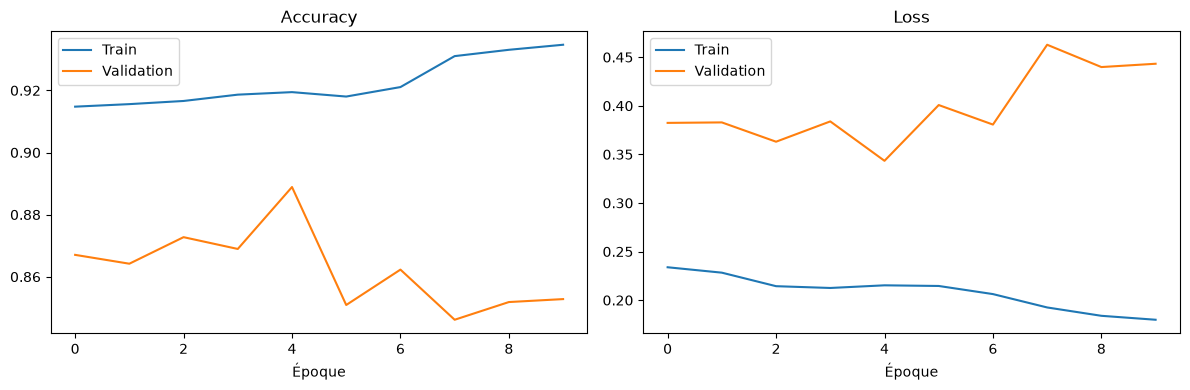

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Époque")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Époque")
plt.legend()

plt.tight_layout()
plt.show()

33/33 [==============================] - 14s 388ms/step

ÉVALUATION DU MODÈLE GOOGLENET : TEST
Nombre d'images : 1054
Accuracy        : 0.8567
Precision macro : 0.8714
Recall macro    : 0.8480
F1-score macro  : 0.8501

Métriques pondérées :
Precision       : 0.8726
Recall          : 0.8567
F1-score        : 0.8557

Rapport de classification :
              precision    recall  f1-score   support

      glioma     0.9939    0.6708    0.8010       243
  meningioma     0.6907    0.8138    0.7472       247
     notumor     0.8939    0.9833    0.9365       300
   pituitary     0.9071    0.9242    0.9156       264

    accuracy                         0.8567      1054
   macro avg     0.8714    0.8480    0.8501      1054
weighted avg     0.8726    0.8567    0.8557      1054



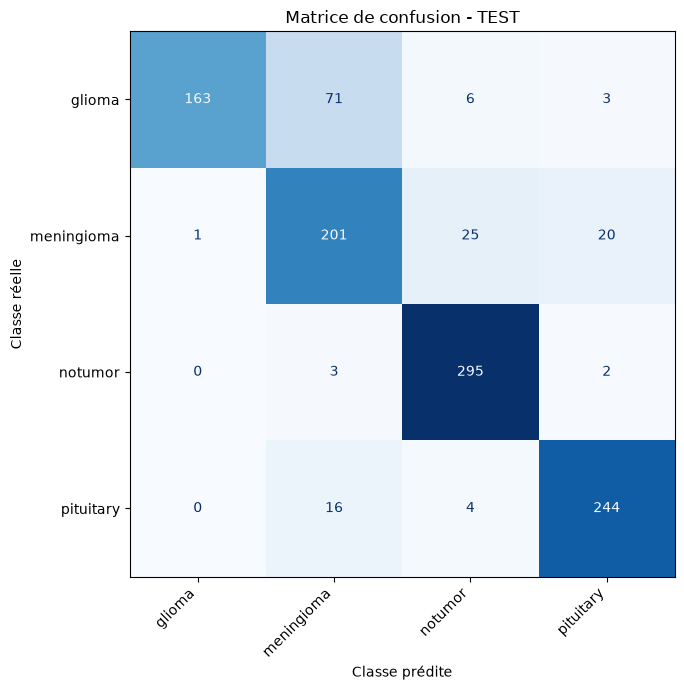


Matrice sauvegardée dans : artifacts\evaluation\confusion_matrix_test.png
Rapport sauvegardé dans : artifacts\evaluation\classification_report_test.txt
154/154 [==============================] - 94s 606ms/step

ÉVALUATION DU MODÈLE GOOGLENET : TRAIN
Nombre d'images : 4916
Accuracy        : 0.2467
Precision macro : 0.2448
Recall macro    : 0.2451
F1-score macro  : 0.2444

Métriques pondérées :
Precision       : 0.2464
Recall          : 0.2467
F1-score        : 0.2461

Rapport de classification :
              precision    recall  f1-score   support

      glioma     0.2249    0.2511    0.2373      1135
  meningioma     0.2242    0.1903    0.2058      1151
     notumor     0.2703    0.2707    0.2705      1400
   pituitary     0.2598    0.2683    0.2640      1230

    accuracy                         0.2467      4916
   macro avg     0.2448    0.2451    0.2444      4916
weighted avg     0.2464    0.2467    0.2461      4916



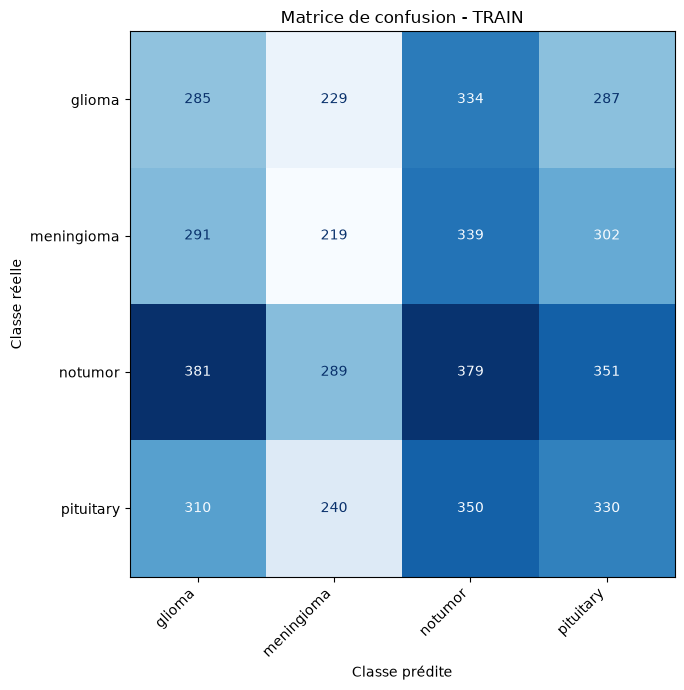


Matrice sauvegardée dans : artifacts\evaluation\confusion_matrix_train.png
Rapport sauvegardé dans : artifacts\evaluation\classification_report_train.txt


In [13]:
from src.classification.evaluate import evaluate_googlenet

test_results = evaluate_googlenet(
    model=model,
    dataset=test_ds,
    class_names=class_names,
    dataset_name="TEST",
    output_dir="artifacts/evaluation",
)

train_results = evaluate_googlenet(
    model=model,
    dataset=train_ds,
    class_names=class_names,
    dataset_name="TRAIN",
    output_dir="artifacts/evaluation",
)



In [14]:
import pandas as pd

metrics_df = pd.DataFrame([
    {
        "Dataset": "Train",
        "Accuracy": train_results["accuracy"],
        "Precision (macro)": train_results["precision_macro"],
        "Recall (macro)": train_results["recall_macro"],
        "F1-score (macro)": train_results["f1_macro"],
    },
    {
        "Dataset": "Test",
        "Accuracy": test_results["accuracy"],
        "Precision (macro)": test_results["precision_macro"],
        "Recall (macro)": test_results["recall_macro"],
        "F1-score (macro)": test_results["f1_macro"],
    },
])

metrics_df.round(4)

,Dataset,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Train,0.2467,0.2448,0.2451,0.2444
1,Test,0.8567,0.8714,0.8480,0.8501
